# Cell 1: Imports and setup


In [1]:

# Cell 1: Imports and setup

import os
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

warnings.filterwarnings("default")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("SVM training environment ready.")


SVM training environment ready.


In [2]:
# Cell 2: Load the 30-component PCA dataset

In [3]:

# Cell 2: Load the 30-component PCA dataset

FEATURE_DIR = Path(
    r"C:\Users\harsh\OneDrive\Documents\BE_Major_Project\DATASET\Features_SWT"
)

MODEL_DIR = FEATURE_DIR / "SVM_Model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FILE = FEATURE_DIR / "pca_swt_train.csv"
TEST_FILE = FEATURE_DIR / "pca_swt_test.csv"

assert TRAIN_FILE.exists(), f"Training file not found: {TRAIN_FILE}"
assert TEST_FILE.exists(), f"Test file not found: {TEST_FILE}"

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nTesting class distribution:")
print(test_df["label"].value_counts())


Training dataset shape: (3883, 33)
Testing dataset shape: (830, 33)

Training class distribution:
label
pituitary     1455
meningioma    1320
glioma        1108
Name: count, dtype: int64

Testing class distribution:
label
meningioma    301
pituitary     295
glioma        234
Name: count, dtype: int64


# Cell 3: Validate and prepare PCA features for SVM

In [4]:

# Cell 3: Validate and prepare PCA features for SVM

metadata_cols = ["filename", "split", "label"]

feature_cols = [
    col for col in train_df.columns
    if col not in metadata_cols
]

test_feature_cols = [
    col for col in test_df.columns
    if col not in metadata_cols
]

# Confirm matching feature columns and expected PCA dimensions
assert feature_cols == test_feature_cols, "Train/test features do not match"
assert len(feature_cols) == 30, (
    f"Expected 30 PCA features, found {len(feature_cols)}"
)

assert train_df["split"].eq("train").all()
assert test_df["split"].eq("test").all()

X_train = train_df[feature_cols].to_numpy(dtype=np.float64)
X_test = test_df[feature_cols].to_numpy(dtype=np.float64)

y_train = train_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

classes = np.sort(np.unique(y_train))

# Check missing values, infinity and label consistency
assert np.isfinite(X_train).all(), "Invalid values in training features"
assert np.isfinite(X_test).all(), "Invalid values in test features"
assert set(y_train) == set(y_test), "Train/test classes do not match"

print("Feature count:", len(feature_cols))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Classes:", classes)
print("Missing/infinite values: None")
print("Validation passed.")


Feature count: 30
Training samples: 3883
Testing samples: 830
Classes: ['glioma' 'meningioma' 'pituitary']
Missing/infinite values: None
Validation passed.


In [5]:
# Cell 4: Baseline SVM with RBF kernel

In [6]:

# Cell 4: Baseline SVM with RBF kernel

from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score

baseline_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight=None,
    probability=False,
    random_state=42
)

start_time = time.time()
baseline_svm.fit(X_train, y_train)
fit_time = time.time() - start_time

# Training predictions are diagnostic only
train_pred = baseline_svm.predict(X_train)
train_accuracy = accuracy_score(y_train, train_pred)

# Five-fold stratified CV using training data only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

start_time = time.time()
cv_scores = cross_val_score(
    baseline_svm,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)
cv_time = time.time() - start_time

print("BASELINE SVM — RBF KERNEL")
print("=" * 40)
print(f"Training accuracy: {train_accuracy:.4f}")
print(f"CV macro-F1:       {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print("Fold scores:", np.round(cv_scores, 4))
print(f"Fit time:          {fit_time:.2f} seconds")
print(f"CV time:           {cv_time:.2f} seconds")


BASELINE SVM — RBF KERNEL
Training accuracy: 0.8089
CV macro-F1:       0.7775 ± 0.0133
Fold scores: [0.7762 0.7707 0.8017 0.7776 0.7615]
Fit time:          0.89 seconds
CV time:           9.27 seconds


# Cell 5: Hyperparameter tuning for SVM

In [7]:

# Cell 5: Hyperparameter tuning for SVM

param_grid = [
    {
        "kernel": ["rbf"],
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", 0.001, 0.01, 0.1],
        "class_weight": [None, "balanced"]
    },
    {
        "kernel": ["linear"],
        "C": [0.1, 1, 10, 100],
        "class_weight": [None, "balanced"]
    },
    {
        "kernel": ["poly"],
        "C": [0.1, 1, 10],
        "gamma": ["scale", "auto"],
        "degree": [2, 3],
        "class_weight": [None, "balanced"]
    }
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

svm_search = GridSearchCV(
    estimator=SVC(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True,
    error_score="raise"
)

start_time = time.time()
svm_search.fit(X_train, y_train)
tuning_time = time.time() - start_time

print(f"\nTuning completed in {tuning_time / 60:.2f} minutes")
print("Best parameters:", svm_search.best_params_)
print(f"Best CV macro-F1: {svm_search.best_score_:.4f}")

results_df = (
    pd.DataFrame(svm_search.cv_results_)
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

display(
    results_df[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "params"
        ]
    ].head(10)
)


Fitting 5 folds for each of 64 candidates, totalling 320 fits

Tuning completed in 4.77 minutes
Best parameters: {'C': 10, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}
Best CV macro-F1: 0.7920


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
0,1,0.791971,0.018826,0.884976,"{'C': 10, 'class_weight': 'balanced', 'gamma':..."
1,2,0.791612,0.021844,0.886501,"{'C': 10, 'class_weight': None, 'gamma': 'scal..."
2,3,0.787621,0.025004,0.874862,"{'C': 100, 'class_weight': None, 'gamma': 0.01..."
3,4,0.787476,0.023257,0.873710,"{'C': 100, 'class_weight': 'balanced', 'gamma'..."
4,5,0.784900,0.014453,0.821337,"{'C': 10, 'class_weight': 'balanced', 'gamma':..."
5,6,0.782335,0.015313,0.877510,"{'C': 1, 'class_weight': 'balanced', 'gamma': ..."
6,7,0.780009,0.014888,0.823206,"{'C': 10, 'class_weight': None, 'gamma': 0.01,..."
7,8,0.778208,0.016238,0.979111,"{'C': 10, 'class_weight': 'balanced', 'gamma':..."
8,9,0.777548,0.013350,0.812541,"{'C': 1, 'class_weight': None, 'gamma': 'scale..."
9,10,0.776667,0.015780,0.874470,"{'C': 1, 'class_weight': None, 'gamma': 0.1, '..."


# Cell 6: Final test-set evaluation for tuned SVM

In [8]:

# Cell 6: Final test-set evaluation for tuned SVM

best_svm = svm_search.best_estimator_

y_test_pred = best_svm.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted")

print("TUNED SVM — TEST SET EVALUATION")
print("=" * 45)
print(f"Best CV Macro-F1:       {svm_search.best_score_:.4f}")
print(f"Test Accuracy:          {test_accuracy:.4f}")
print(f"Test Balanced Accuracy: {test_balanced_accuracy:.4f}")
print(f"Test Macro-F1:          {test_macro_f1:.4f}")
print(f"Test Weighted F1:       {test_weighted_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=classes,
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


TUNED SVM — TEST SET EVALUATION
Best CV Macro-F1:       0.7920
Test Accuracy:          0.8012
Test Balanced Accuracy: 0.8005
Test Macro-F1:          0.7993
Test Weighted F1:       0.8000

Classification Report:
              precision    recall  f1-score   support

      glioma     0.7924    0.7991    0.7957       234
  meningioma     0.8307    0.8804    0.8548       301
   pituitary     0.7745    0.7220    0.7474       295

    accuracy                         0.8012       830
   macro avg     0.7992    0.8005    0.7993       830
weighted avg     0.7999    0.8012    0.8000       830



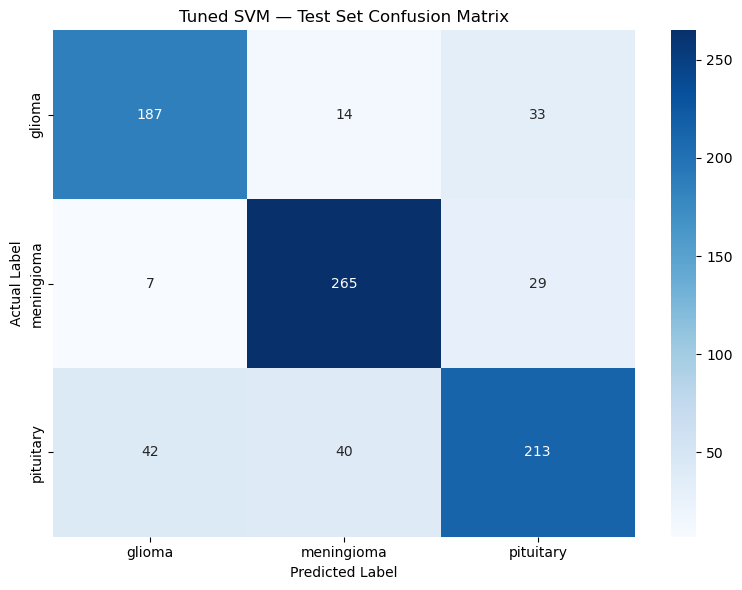

Confusion Matrix:
[[187  14  33]
 [  7 265  29]
 [ 42  40 213]]


In [9]:

# Cell 7: Confusion Matrix — Tuned SVM

cm = confusion_matrix(y_test, y_test_pred, labels=classes)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Tuned SVM — Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)


In [10]:
# Load original SWT features — no PCA

In [11]:

# Load original SWT features — no PCA

direct_train_df = pd.read_csv(FEATURE_DIR / "swt_train.csv")
direct_test_df = pd.read_csv(FEATURE_DIR / "swt_test.csv")

metadata_cols = ["filename", "split", "label"]
direct_feature_cols = [
    col for col in direct_train_df.columns
    if col not in metadata_cols
]

X_train = direct_train_df[direct_feature_cols].to_numpy(dtype=np.float64)
X_test = direct_test_df[direct_feature_cols].to_numpy(dtype=np.float64)

y_train = direct_train_df["label"].to_numpy()
y_test = direct_test_df["label"].to_numpy()

classes = sorted(np.unique(y_train))

assert len(direct_feature_cols) == 32, (
    f"Expected 32 SWT features, found {len(direct_feature_cols)}"
)
assert direct_feature_cols == [
    col for col in direct_test_df.columns if col not in metadata_cols
]
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

print("Direct SWT features loaded successfully.")
print("Feature count:", len(direct_feature_cols))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Classes:", classes)


Direct SWT features loaded successfully.
Feature count: 32
Training shape: (3883, 32)
Testing shape: (830, 32)
Classes: ['glioma', 'meningioma', 'pituitary']


# Baseline SVM using 32 SWT features — no PCA

In [15]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

print("Missing imports fixed.")


Missing imports fixed.


In [16]:

# Baseline SVM using 32 SWT features — no PCA

baseline_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight=None,
        random_state=RANDOM_STATE
    ))
])

start_time = time.time()
baseline_svm.fit(X_train, y_train)
fit_time = time.time() - start_time

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

start_time = time.time()
cv_scores = cross_val_score(
    baseline_svm,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)
cv_time = time.time() - start_time

print("DIRECT SWT SVM — BASELINE")
print("=" * 45)
print(f"Training accuracy: {baseline_svm.score(X_train, y_train):.4f}")
print(f"CV Macro-F1 mean : {cv_scores.mean():.4f}")
print(f"CV Macro-F1 std  : {cv_scores.std():.4f}")
print("CV fold scores   :", np.round(cv_scores, 4))
print(f"Fit time         : {fit_time:.2f} seconds")
print(f"CV time          : {cv_time:.2f} seconds")


DIRECT SWT SVM — BASELINE
Training accuracy: 0.8089
CV Macro-F1 mean : 0.7775
CV Macro-F1 std  : 0.0135
CV fold scores   : [0.7762 0.7692 0.8016 0.779  0.7615]
Fit time         : 0.79 seconds
CV time          : 9.55 seconds


In [17]:
# Tune SVM on 32 original SWT features — no PCA

In [18]:

# Tune SVM on 32 original SWT features — no PCA

param_grid = [
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.001, 0.01, 0.1],
        "svm__class_weight": [None, "balanced"]
    },
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__class_weight": [None, "balanced"]
    },
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10],
        "svm__gamma": ["scale", "auto"],
        "svm__degree": [2, 3],
        "svm__class_weight": [None, "balanced"]
    }
]

svm_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(random_state=RANDOM_STATE))
    ]),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True,
    error_score="raise"
)

start_time = time.time()
svm_search.fit(X_train, y_train)
tuning_time = time.time() - start_time

print("\nDIRECT SWT SVM — TUNING RESULTS")
print("=" * 50)
print("Best parameters:", svm_search.best_params_)
print(f"Best CV Macro-F1: {svm_search.best_score_:.4f}")
print(f"Tuning time: {tuning_time / 60:.2f} minutes")

best_idx = svm_search.best_index_
mean_train_f1 = svm_search.cv_results_["mean_train_score"][best_idx]
print(f"Best model CV training Macro-F1: {mean_train_f1:.4f}")
print(f"Train-CV gap: {mean_train_f1 - svm_search.best_score_:.4f}")


Fitting 5 folds for each of 64 candidates, totalling 320 fits

DIRECT SWT SVM — TUNING RESULTS
Best parameters: {'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best CV Macro-F1: 0.7922
Tuning time: 4.71 minutes
Best model CV training Macro-F1: 0.8850
Train-CV gap: 0.0928


# Test evaluation — Direct SWT SVM, no PCA

In [19]:

# Test evaluation — Direct SWT SVM, no PCA

best_svm = svm_search.best_estimator_
y_test_pred = best_svm.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted")

print("TUNED DIRECT SWT SVM — TEST SET EVALUATION")
print("=" * 50)
print(f"Best CV Macro-F1:       {svm_search.best_score_:.4f}")
print(f"Test Accuracy:          {test_accuracy:.4f}")
print(f"Test Balanced Accuracy: {test_balanced_accuracy:.4f}")
print(f"Test Macro-F1:           {test_macro_f1:.4f}")
print(f"Test Weighted F1:        {test_weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=classes,
    target_names=classes,
    digits=4,
    zero_division=0
))


TUNED DIRECT SWT SVM — TEST SET EVALUATION
Best CV Macro-F1:       0.7922
Test Accuracy:          0.8012
Test Balanced Accuracy: 0.8005
Test Macro-F1:           0.7993
Test Weighted F1:        0.8000

Classification Report:
              precision    recall  f1-score   support

      glioma     0.7924    0.7991    0.7957       234
  meningioma     0.8307    0.8804    0.8548       301
   pituitary     0.7745    0.7220    0.7474       295

    accuracy                         0.8012       830
   macro avg     0.7992    0.8005    0.7993       830
weighted avg     0.7999    0.8012    0.8000       830

